# Exploring Segmentation Pipelines in StackGP

In [198]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [199]:

from StackGP import *
from skimage.exposure import *
from skimage.transform import resize
import imageio
import numpy as np
import matplotlib.pyplot as plt
from see.Segmentors import *
from see.Segment_Fitness import FitnessFunction, FF_ML2DHD
from see.Segment_Fitness import countMatches, countsets

### Image operators and supporting functions

In [200]:
# bound a random value between min and max
def boundVal(val, minVal, maxVal):
    if val<minVal:
        return minVal
    elif val>maxVal:
        return maxVal
    else:
        return val

def seg_color_threshold(img, alpha1, alpha2, beta1, beta2, gamma1, gamma2):
    seg = segmentor()
    seg.params["algorithm"] = "ColorThreshold"

    seg.params["alpha1"] = boundVal(alpha1, 0, 1)
    seg.params["alpha2"] = boundVal(alpha2, 0, 1)
    seg.params["beta1"] = boundVal(beta1, 0, 1)
    seg.params["beta2"] = boundVal(beta2, 0, 1)
    seg.params["gamma1"] = boundVal(gamma1, 0, 1)
    seg.params["gamma2"] = boundVal(gamma2, 0, 1)

    return seg.evaluate(img)
seg_color_threshold.__repr__ = lambda: "color_threshold"


def seg_felzenszwalb(img, alpha1, alpha2, beta1):
    seg = segmentor()
    seg.params["algorithm"] = "Felzenszwalb"

    seg.params["alpha1"] = boundVal(alpha1, 0, 1)
    seg.params["alpha2"] = boundVal(alpha2, 0, 1)
    seg.params["beta1"] = boundVal(beta1, 0.01, 1)

    return seg.evaluate(img)
seg_felzenszwalb.__repr__ = lambda: "felzenszwalb"


def seg_slic(img, alpha1, beta1, n_segments, max_num_iter):
    seg = segmentor()
    seg.params["algorithm"] = "Slic"

    seg.params["alpha1"] = boundVal(alpha1, 0, 1)
    seg.params["beta1"] = boundVal(beta1, 0.01, 1)
    seg.params["n_segments"] = max(2, int(n_segments * 200))
    seg.params["max_num_iter"] = max(1, int(max_num_iter * 20))

    return seg.evaluate(img)
seg_slic.__repr__ = lambda: "slic"


def seg_slic0(img, alpha1, beta1, n_segments, max_num_iter):
    seg = segmentor()
    seg.params["algorithm"] = "SlicO"

    seg.params["alpha1"] = boundVal(alpha1, 0, 1)
    seg.params["beta1"] = boundVal(beta1, 0.01, 1)
    seg.params["n_segments"] = max(2, int(n_segments * 200))
    seg.params["max_num_iter"] = max(1, int(max_num_iter * 20))

    return seg.evaluate(img)
seg_slic0.__repr__ = lambda: "slic0"


def seg_quick_shift(img, alpha1):
    seg = segmentor()
    seg.params["algorithm"] = "QuickShift"
    seg.params["alpha1"] = boundVal(alpha1, 0, 1)

    return seg.evaluate(img)
seg_quick_shift.__repr__ = lambda: "quick_shift"

def seg_morph_chan_vese(img, alpha1, beta1, beta2, n_segments, max_num_iter):
    seg = segmentor()
    seg.params["algorithm"] = "Morphological_Chan_Vese"

    seg.params["alpha1"] = boundVal(alpha1, 0, 1)
    seg.params["beta1"] = boundVal(beta1, 0, 1)
    seg.params["beta2"] = boundVal(beta2, 0, 1)
    seg.params["n_segments"] = int(boundVal(n_segments, 0, 1) * 1.999)
    seg.params["max_num_iter"] = max(1, int(boundVal(max_num_iter, 0, 1) * 50))

    return seg.evaluate(img)
seg_morph_chan_vese.__repr__ = lambda: "morph_chan_vese"

def seg_morph_gac(img, alpha1, alpha2, beta1, beta2, n_segments, max_num_iter):
    seg = segmentor()
    seg.params["algorithm"] = "MorphGeodesicActiveContour"

    seg.params["alpha1"] = boundVal(alpha1, 0, 1)
    seg.params["alpha2"] = boundVal(alpha2, 0, 1)

    # Avoid zero or negative gradient parameters
    seg.params["beta1"] = boundVal(beta1, 0.01, 1)
    seg.params["beta2"] = boundVal(beta2, 0.01, 1)

    # SEE uses n_segments % 2 to choose initialization
    seg.params["n_segments"] = int(boundVal(n_segments, 0, 1) * 1.999)

    # Integer iteration count
    seg.params["max_num_iter"] = max(1, int(boundVal(max_num_iter, 0, 1) * 50))

    return seg.evaluate(img)
seg_morph_gac.__repr__ = lambda: "morph_gac"

In [201]:
imageOps = [
    seg_felzenszwalb,
    seg_color_threshold,
    seg_slic,
    seg_slic0,
    seg_quick_shift,
    seg_morph_chan_vese,
    seg_morph_gac
]

expArities = {
    "felzenszwalb": 3,
    "color_threshold": 6,
    "slic": 4,
    "slic0": 4,
    "quick_shift": 1,
    "morph_chan_vese": 5,
    "morph_gac": 6
}

def ranVal():
    return random.random()
imgConst= [ranVal]

### Model evaluation functions

In [202]:
def see(img):
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    return

# replace pixels greater than 1 with 1, less than 0 with 0
def clipImage(img):
    img[img>1]=1
    img[img<0]=0
    return img

def getImgArity(imgOp):
    return expArities[imgOp.__repr__()]

def evaluateGPImgModel(model,inputData): #Evaluates a model numerically
    response=evModImgHelper(model[1],model[0],[],inputData)[2]
    
    return response
def evModImgHelper(varStack,opStack,tempStack,img): #Recursive helper function for evaluateGPModel
    stack1=varStack
    stack2=opStack
    stack3=tempStack

    if not isinstance(img, np.ndarray): return [stack1, stack2, np.nan]
    
    # check if all pixel values are same
    if np.all(img == img.flat[0]):
        return [stack3,stack2,stack1]
    if len(stack2)==0:
        return [stack3,stack2,stack1]
    op=stack2[0]
    stack2=stack2[1:]
    
    
        
    patt=getImgArity(op)
    while patt>len(stack3):
        stack3=[stack1[0]]+stack3
        stack1=stack1[1:]

    # print("stack3: ", stack3, " patt: ", patt, " data: ", np.mean(img), " op: ", op)
    try:
        temp = op(img, *reverseList(stack3[:patt]))
    # except TypeError:
    #     print("Type Error -- stack3: ", stack3, " patt: ", patt, " data: ", img, " op: ", op)
    #     temp=np.nan
    except TypeError as e:
        print(f"TypeError in {op.__name__}: {e}")
        print("Parameters:", reverseList(stack3[:patt]))
        print("Image shape:", np.shape(img))
        temp = np.nan
    except OverflowError:
        temp=np.nan
    stack3=stack3[patt:]
    #stack3=[temp]+stack3
    
    if len(stack2)>0:
        stack1,stack2,stack3=evModImgHelper(stack1,stack2,stack3,temp)
        
    return [stack1,stack2,temp]

def modelImgArity(model): #Returns the total arity of a model
    return sum([getImgArity(i) for i in model[0]])

def generateRandomImgModel(ops,const,maxLength):  #Generates a random GP model
    prog = buildEmptyModel()                             #Generate an empty model with correct structure
    varChoices=const                           #All variable and constants choices
    prog[0]=np.array(np.random.choice(ops,random.randint(1,maxLength)),dtype=object) #Choose random operators
    countVars=modelImgArity(prog)    #Count how many variables/constants are needed
    prog[1]=np.random.choice(varChoices,countVars).tolist()       #Choose random variables/constants
    prog[1]=[i() if (callable(i) and i.__name__!='<lambda>' )else i for i in prog[1]] #If function then evaluate
    return prog
def initializeGPImgModels(ops=imageOps,const=defaultConst(),numberOfModels=100,maxLength=10): # generate random linear program
    prog=[[],[],[]]
    # prog stores [Operators, VarConst, QualityMetrics]
    
    models=[generateRandomImgModel(ops,const,maxLength) for i in range(numberOfModels)] #Generate models
    
    return models

In [203]:
[op for op in imageOps if getImgArity(op)==1 and op!='pop']

[<function __main__.seg_quick_shift(img, alpha1)>]

In [204]:
def imgmutate(model,variables,ops=defaultOps(),const=defaultConst(),maxLength=10):
    newModel=copy.deepcopy(model)
    newModel[0]=np.array(newModel[0],dtype=object).tolist()
    mutationType=random.randint(0,10)

    varChoices=[variableSelect(i) for i in range(variables)]+const
    opChoice=0
    varChoice=0
    
    tmp=0
    
    if mutationType==0: #single operator mutation
        opChoice=random.randint(0,len(newModel[0])-1)
        if len(newModel[0])>0:
            newModel[0][opChoice]=np.random.choice([i for i in ops] )
               
    elif mutationType==1: #single variable mutation
        varChoice=np.random.choice(varChoices)
        if callable(varChoice) and varChoice.__name__!='<lambda>':
            varChoice=varChoice()
        newModel[1][random.randint(0,len(newModel[1])-1)]=varChoice
    
    elif mutationType==2: #insertion mutation to top of stack
        opChoice=np.random.choice(ops)
        newModel[0]=[opChoice]+newModel[0]
        while modelImgArity(newModel)>len(newModel[1]):
            varChoice=np.random.choice(varChoices)
            if callable(varChoice) and varChoice.__name__!='<lambda>':
                varChoice=varChoice()
            newModel[1]=[varChoice]+newModel[1]
        
    elif mutationType==3: #deletion mutation from top of stack
        if len(newModel[0])>1:
            opChoice=random.randint(1,len(newModel[0])-1)
            newModel[0]=newModel[0][-opChoice:]
            newModel[1]=newModel[1][-modelImgArity([newModel[0]]):]
            
    elif mutationType==4: #insertion mutation to bottom of stack
        opChoice=np.random.choice([i for i in ops])
        newModel[0].append(opChoice)
        
    elif mutationType==5: #mutation via crossover with random model
        newModel=recombination2pt(newModel,generateRandomModel(variables,ops,const,maxLength))[0]

    # elif mutationType==6: #single operator insertion mutation
    #     singleOps=[op for op in ops if getImgArity(op)==1 and op!='pop']
    #     #singleOps.append('pop')
    #     pos=random.randint(0,len(newModel[0])-1)
    #     newModel[0].insert(pos,np.random.choice(singleOps))
    
    elif mutationType == 6:  # single operator insertion mutation
        singleOps = [
            op for op in ops
            if getImgArity(op) == 1 and op != 'pop'
        ]

        if len(singleOps) > 0:
            pos = random.randint(0, len(newModel[0]))
            newModel[0].insert(pos, random.choice(singleOps))


    elif mutationType>=7: #nudge numeric constant
        pos=get_numeric_indices(newModel[1])
        if(len(pos)>0): #If there are numeric constants
            pos=random.choice(pos)
            newModel[1][pos]=newModel[1][pos]+np.random.normal(-.05,.05) 
            
    if modelImgArity(newModel)<len(newModel[1]):
        newModel[1]=newModel[1][:modelImgArity(newModel)]
    elif modelImgArity(newModel)>len(newModel[1]):
        newModel[1]=newModel[1]+[np.random.choice(varChoices) for i in range(modelImgArity(newModel)-len(newModel[1]))]
    newModel[1]=[varChoice() if callable(varChoice) and varChoice.__name__!='<lambda>' else varChoice for varChoice in newModel[1]]         
    newModel[0]=np.array(newModel[0],dtype=object)
    return newModel


def imgevolve(inputData, responseData, generations=100, maxLength=3, ops=copy.deepcopy(imageOps), const=imgConst, variableNames=[], mutationRate=79, crossoverRate=11, spawnRate=10, extinction=False,extinctionRate=10,elitismRate=50,popSize=300,maxComplexity=100,align=True,initialPop=[],timeLimit=300,capTime=False,tourneySize=5,tracking=False,liveTracking=False,liveTrackingInterval=1,modelEvaluationMetrics=[fitness,stackGPModelComplexity],dataSubsample=False,samplingMethod=randomSubsample,alternateObjectives=[],alternateObjFrequency=10,allowEarlyTermination=False,earlyTerminationThreshold=0):
    
    metrics=modelEvaluationMetrics

    fullInput,fullResponse=copy.deepcopy(inputData),copy.deepcopy(responseData)
    inData=copy.deepcopy(fullInput)
    resData=copy.deepcopy(fullResponse)
    models=initializeGPImgModels(ops,const,popSize,maxLength=maxLength)
    models=models+initialPop
    startTime=time.perf_counter()
    bestFits=[]
    if liveTracking:
        fig, ax = plt.subplots(figsize=(20,10))
        ckTime=time.perf_counter()
    for i in range(generations):
        if capTime and time.perf_counter()-startTime>timeLimit:
            break
        if len(alternateObjectives)>0 and (i+1)%alternateObjFrequency==0:
            metrics=modelEvaluationMetrics[:1]+alternateObjectives
        else:
            metrics=modelEvaluationMetrics
        if dataSubsample:
            inData,resData=samplingMethod(fullInput,fullResponse,generations=generations,generation=i)
        for mods in models:
            mods[2] = seeStackGPFitnessAndTime(mods, inData, resData)
        models=removeIndeterminateModels(models)
        if allowEarlyTermination and min([mods[2][0] for mods in models])<=earlyTerminationThreshold:
            print("Early termination at generation ", i)
            break
        if tracking or liveTracking:
            bestFits.append(min([mods[2][0] for mods in paretoTournament(models)]))
        if liveTracking and time.perf_counter()-ckTime>liveTrackingInterval:
            ax.clear()
            ax.plot(bestFits)
            ax.set_title(f"Best Model: {bestFits[-1]:.2f} at Generation {(i+1)}")
            ax.set_xlabel("Generations")
            ax.set_ylabel("Fitness")
            clear_output(wait=True) 
            display(fig)    
            #plt.show()        
            plt.close(fig)
            ckTime=time.perf_counter()        

        #paretoModels=paretoTournament(models)
        paretoModels=selectModels(models,elitismRate/100*popSize if elitismRate/100*popSize<len(models) else len(models))
        if extinction and i%extinctionRate==0 and i>0:
            models=initializeGPImgModels(ops,const,popSize)
            for mods in models:
                mods[2] = seeStackGPFitnessAndTime(mods, inData, resData)
        
        models=tournamentModelSelection(models,popSize,tourneySize)
        
        crossoverPairs=random.sample(models,round(crossoverRate/100*popSize))
        toMutate=random.sample(models,round(mutationRate/100*popSize))
        
        childModels=paretoModels
        
        for j in range(round(len(crossoverPairs)/2)-1):
            childModels=childModels+recombination2pt(crossoverPairs[j],crossoverPairs[j+round(len(crossoverPairs)/2)])
        
        for j in toMutate:
            childModels=childModels+[imgmutate(j,0,ops,const)]
        
        childModels=childModels+initializeGPImgModels(ops,const,round(spawnRate/100*popSize))
        
        childModels=deleteDuplicateModels(childModels)
        childModels=[model for model in childModels if stackGPModelComplexity(model)<maxComplexity]
        
        #for mods in childModels:
        #    mods[2] = seeStackGPFitnessAndTime(mods, inData, resData)
        #childModels=removeIndeterminateModels(childModels)
        
        if len(childModels)<popSize:
            childModels=childModels+initializeGPImgModels(ops,const,popSize-len(childModels))
        
        models=copy.deepcopy(childModels)
        
    
    for mods in models:
        mods[2] = seeStackGPFitnessAndTime(mods, inData, resData)
    #models=[trimModel(mod) for mod in models]
    models=deleteDuplicateModels(models)
    models=removeIndeterminateModels(models)
    models=sortModels(models)
    #if align:
    #    models=[alignGPModel(mods,fullInput,fullResponse) for mods in models]
    
    if tracking:
        bestFits.append(min([mods[2][0] for mods in paretoTournament(models)])) 
        plt.figure()
        plt.plot(bestFits)
        plt.title("Fitness over Time")
        plt.xlabel("Generations")
        plt.ylabel("Fitness")
        plt.show()
    
    return models


/var/folders/61/0blnvg4x66v34d11h0nd8b2m0000gn/T/ipykernel_93888/1819268044.py:1: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread('../Image_data/Examples/AA_Chameleon.jpg')


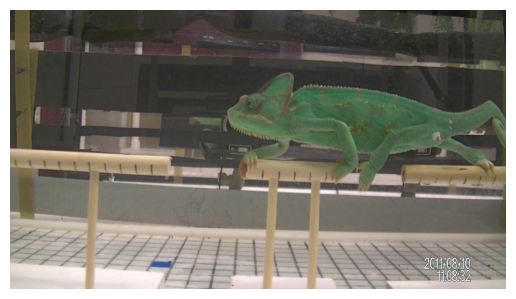

In [205]:
img = imageio.imread('../Image_data/Examples/AA_Chameleon.jpg')
#img = imageio.imread('../Image_data/Examples/Waterbottle.jpg')
#img = imageio.imread('../Image_data/Examples/ants.jpg')
#img = imageio.imread('../Image_data/Examples/a_walk_in_the_park.jpg')
# convert to float image
img=img.astype(float)/255.0
see(img)

/var/folders/61/0blnvg4x66v34d11h0nd8b2m0000gn/T/ipykernel_93888/2840883698.py:1: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  gt = imageio.imread('../Image_data/Examples/AA_Chameleon_GT.png')


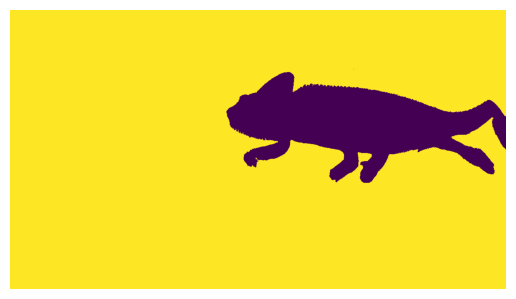

In [206]:
gt = imageio.imread('../Image_data/Examples/AA_Chameleon_GT.png')
#gt = imageio.imread('../Image_data/Examples/Waterbottle_GT.png')
#gt = imageio.imread('../Image_data/Examples/ants_GT.png')
#gt = imageio.imread('../Image_data/Examples/a_walk_in_the_park_GT.png')
# convert to float image
gt=gt.astype(float)
see(gt)

In [207]:
def seeStackGPFitnessAndTime(model, inputData, responseData):
    start = time.perf_counter()

    inferred = evaluateGPImgModel(model, inputData)

    runtime = time.perf_counter() - start
    fitness = FitnessFunction(inferred, responseData)[0]

    return [fitness, runtime]

In [208]:
# Reduce image resolution to 25%
scale = 0.25

full_img = img.copy()
full_gt = gt.copy()

img = resize(
    img,
    (int(img.shape[0] * scale), int(img.shape[1] * scale)),
    preserve_range=True,
    anti_aliasing=True
)

gt = resize(
    gt,
    img.shape[:2],
    order=0,
    preserve_range=True,
    anti_aliasing=False
)

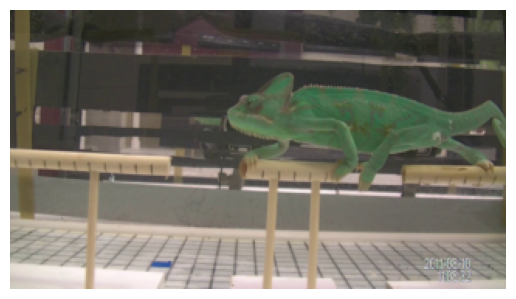

In [209]:
see(img)

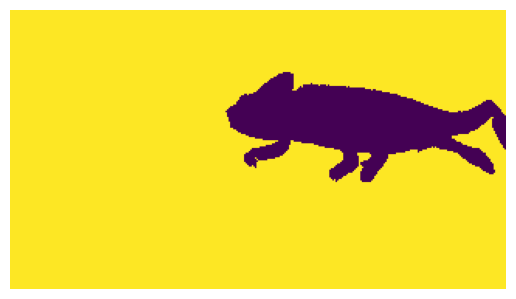

In [210]:
see(gt)

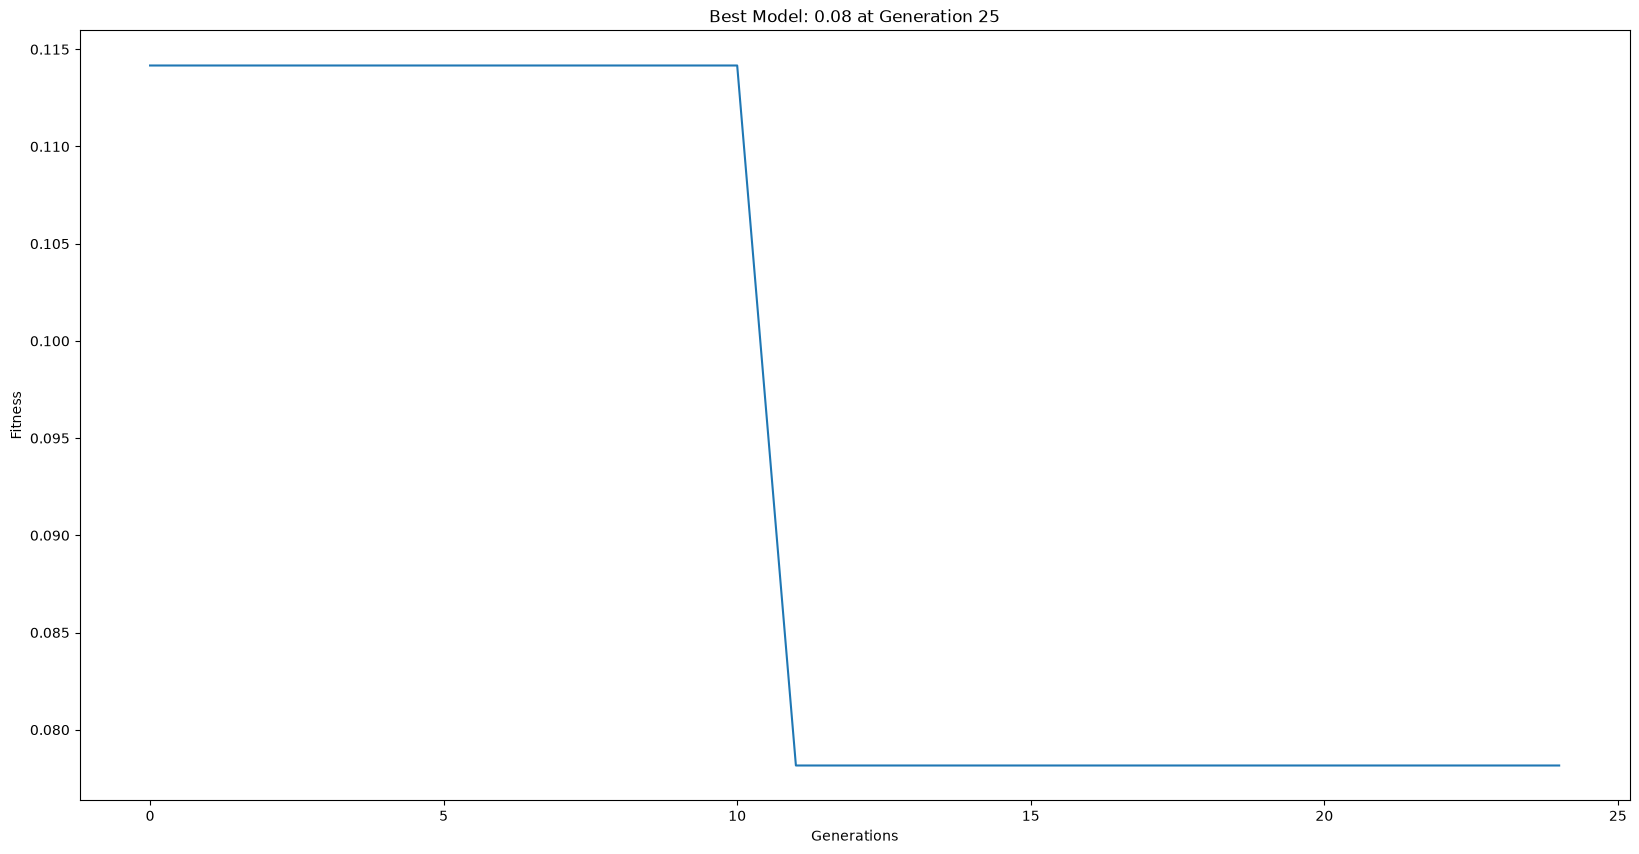

In [ ]:
models=imgevolve(img,gt,modelEvaluationMetrics=seeStackGPFitnessAndTime,liveTracking=True,liveTrackingInterval=5,popSize=20,tourneySize=3,generations=50,initialPop=[],elitismRate=5, maxLength=5)

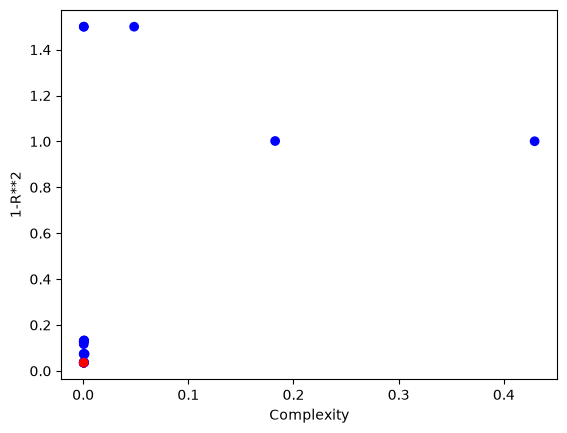

In [ ]:
plotModels(models)

In [ ]:
models[0]

[array([<function seg_color_threshold at 0x31d8bbed0>], dtype=object),
 [0.03291422369660102,
  0.8081065071254895,
  0.7872233022883297,
  0.754033422251028,
  0.5396264082580836,
  0.23173552469545072],
 [np.float64(0.0356669211911747), 0.0005346250254660845]]

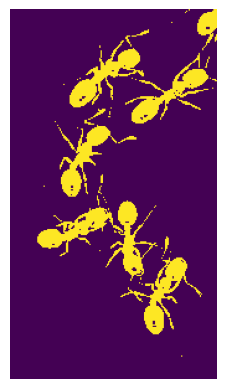

In [ ]:
see(evaluateGPImgModel(models[0],img))

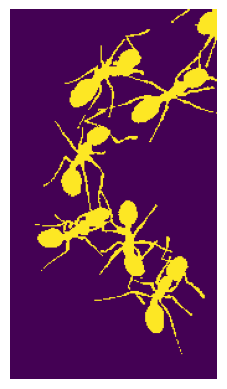

In [ ]:
see(gt)